# Reinforcement learning on a grid

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/3_robot_learning/06_reinforcement_learning.ipynb) &nbsp; Guide note: [guide-reinforcement-learning](https://www.matthewwnuk.com/guide-reinforcement-learning.html#maths)

Reinforcement learning has no demonstrator. The agent tries actions, receives a reward, and adjusts.
A 6 x 9 grid with walls, a goal (+1) and a hazard (-1) is small enough to solve exactly, which makes it
a good place to see what a value function is, why trial and error is expensive, and what reward shaping
does.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from guide_utils import grid as G, style
style.use()

def draw(ax, values=None, policy=None, title=""):
    vmax = max(values.values()) if values else 1
    for r in range(G.H):
        for c in range(G.W):
            s = (r, c); color = "#59636B" if s in G.WALLS else style.TEAL if s == G.GOAL else style.RED if s == G.PIT else (plt.cm.GnBu(max(values[s], 0) / vmax * 0.8) if values else style.SOFT)
            ax.add_patch(Rectangle((c, r), 1, 1, fc=color, ec="white", lw=1.5))
            if policy and s in G.STARTS: dy, dx = G.ACTIONS[policy[s]]; ax.arrow(c + 0.5 - 0.2 * dx, r + 0.5 - 0.2 * dy, 0.4 * dx, 0.4 * dy, head_width=0.16, color=style.INK, length_includes_head=True)
    ax.set_xlim(0, G.W); ax.set_ylim(G.H, 0); ax.set_aspect("equal"); style.bare(ax); ax.set_title(title)

## Reward and value

The reward marks two cells. The value of a cell is the return the agent can expect from it under the
best policy. Value iteration computes it by applying the Bellman equation until nothing changes:
the value of a state is the best, over actions, of immediate reward plus discounted value of what follows.

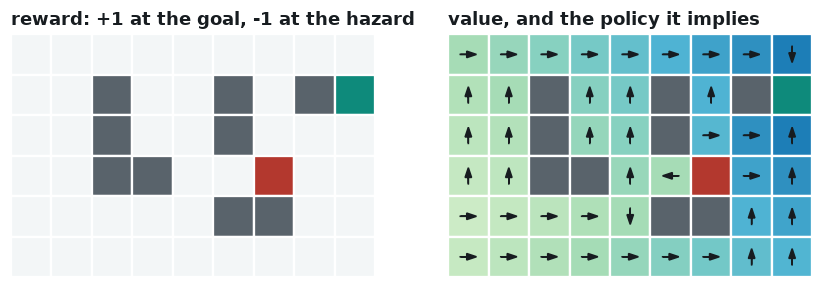

value of the start corner 0.33, of the cell next to the goal 0.99


In [3]:
V, best = G.value_iteration(); fig, ax = plt.subplots(1, 2, figsize=(9.4, 3.2))
draw(ax[0], title="reward: +1 at the goal, -1 at the hazard"); draw(ax[1], V, best, "value, and the policy it implies"); plt.show()
print(f"value of the start corner {V[(5, 0)]:.2f}, of the cell next to the goal {V[(0, 8)]:.2f}")

## Q-learning: the same answer by trial and error

The agent does not know the rules. After every step it nudges its estimate of the action's value toward
reward + discount x (best value at the next state).

In [4]:
def q_learning(budgets, seed, shaping=None, eps=0.15, alpha=0.2):
    rng = np.random.default_rng(seed); Q = {s: np.zeros(4) for s in G.FREE}; steps = 0; out = []
    dist = {s: abs(s[0] - G.GOAL[0]) + abs(s[1] - G.GOAL[1]) for s in G.FREE}
    while len(out) < len(budgets):
        s = G.STARTS[rng.integers(len(G.STARTS))]
        for _ in range(60):
            i = rng.integers(4) if rng.random() < eps else int(np.argmax(Q[s] + rng.random(4) * 1e-6))        # explore sometimes
            s2, r, done = G.step(s, i, rng)
            if shaping == "potential": r += 0.05 * (G.GAMMA * -dist[s2] + dist[s])                             # gamma * phi(s') - phi(s)
            if shaping == "naive": r += 0.05 * (dist[s2] < dist[s])                                           # a bonus for moving closer
            Q[s][i] += alpha * (r + (0 if done else G.GAMMA * Q[s2].max()) - Q[s][i]); s = s2; steps += 1
            if len(out) < len(budgets) and steps >= budgets[len(out)]: out.append(G.evaluate(lambda z: int(np.argmax(Q[z])), rng))
            if done: break
    return out, Q

budgets = np.unique(np.round(np.logspace(2, 4.6, 14)).astype(int)); ql = np.mean([q_learning(budgets, s)[0] for s in range(6)], 0) * 100

## Imitation on the same task

For comparison, copy an expert. Record the optimal policy's actions and repeat whatever it did in each
state. In states never seen, act at random.

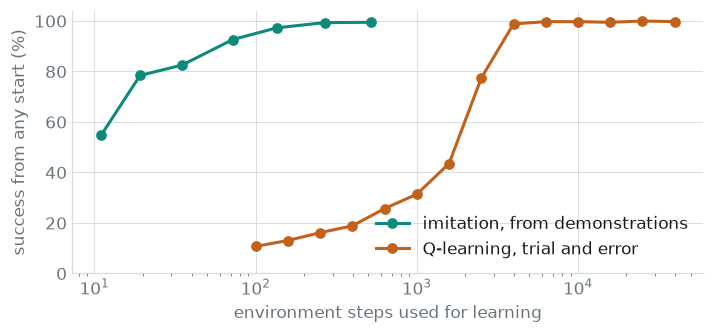

steps to reach 90% success: imitation about 72, Q-learning about 3981


In [5]:
def imitation(n_demos, seed):
    rng = np.random.default_rng(seed); seen = {}; steps = 0
    for _ in range(n_demos):
        s = G.STARTS[rng.integers(len(G.STARTS))]
        for _ in range(60):
            seen.setdefault(s, np.zeros(4))[best[s]] += 1; steps += 1; s, _r, done = G.step(s, best[s], rng)
            if done: break
    return steps, G.evaluate(lambda z: int(np.argmax(seen[z])) if z in seen else int(rng.integers(4)), rng)
demos = [1, 2, 4, 8, 16, 32, 64]; im = np.array([np.mean([imitation(n, s) for s in range(6)], 0) for n in demos])
plt.figure(figsize=(7.4, 3.1)); plt.plot(im[:, 0], im[:, 1] * 100, marker="o", label="imitation, from demonstrations"); plt.plot(budgets, ql, marker="o", label="Q-learning, trial and error")
plt.xscale("log"); plt.ylim(0, 104); plt.xlabel("environment steps used for learning"); plt.ylabel("success from any start (%)"); plt.legend(); plt.show()
reach = lambda x, y: int(x[np.argmax(y >= 90)]); print(f"steps to reach 90% success: imitation about {reach(im[:, 0], im[:, 1] * 100)}, Q-learning about {reach(budgets, ql)}")

The gap is the price of having no teacher. The comparison is not one-sided: imitation needed an expert to
exist, and it can only match that expert.

## Reward shaping

A sparse reward says nothing until the agent stumbles on the goal. Shaping adds a signal along the way.
The safe form is based on a potential: whatever is gained by moving toward the goal is lost by moving
away, so no loop can collect reward. A naive bonus for moving closer has no such guarantee.

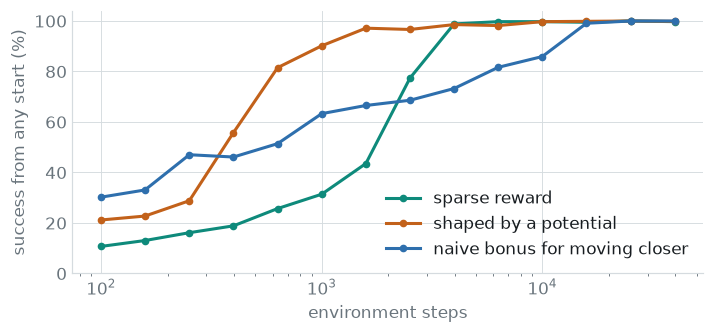

In [6]:
plt.figure(figsize=(7.4, 3.1))
for name, sh in (("sparse reward", None), ("shaped by a potential", "potential"), ("naive bonus for moving closer", "naive")):
    c = np.mean([q_learning(budgets, s, sh)[0] for s in range(6)], 0) * 100; plt.plot(budgets, c, marker="o", ms=4, label=name)
plt.xscale("log"); plt.ylim(0, 104); plt.xlabel("environment steps"); plt.ylabel("success from any start (%)"); plt.legend(); plt.show()

## Things to try

- Set the exploration rate `eps` to zero. What happens, and why?
- Lower the discount `G.GAMMA` to 0.5 and recompute the value function. Which cells change most?
- Make the naive bonus larger than the goal reward. Does the agent still go to the goal?